# F4.4 — Convergencia con la Tabla 11

**Procedencia.** `python -m src.fase4.convergencia --root … --resoluciones results/f44_convergencia/resoluciones.json`, una sola vez, con el árbol limpio (`results/f44_convergencia/resultados.json`, `spearman_por_muestra.csv`, `parches.npz`). Este notebook no recalcula nada: lee esas salidas, comprueba las cifras contra `results/canonical_numbers.json` (`f44.*`) y dibuja.

**Regla de lectura** (`docs/plan_fase4.md`, F4.4, «qué se afirma / qué no»).
- IC del Spearman medio por encima de 0: en `val`, el mapa pone más masa donde el descriptor es más alto (convergencia). No se afirma que el modelo calcule ese descriptor.
- IC que contiene 0 o queda por debajo: sin convergencia local entre mapa y descriptor. No se afirma que el descriptor sea irrelevante para la clase (es significativo en la Tabla 11).
- **Lorenz**: F4.3 reporta sus mapas como «dependientes de la cabeza, sin validación por datos». Su convergencia es descriptiva y no es evidencia de lo que aprendió el clasificador.
- La tabla ablación ↔ descriptores es una clasificación orientativa; el contraste A11 de la Fase 5 se cita sin combinarlo.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src', REPO / 'src' / 'training'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style
from src.fase4 import convergencia as cv

style.apply()
D = REPO / 'results' / 'f44_convergencia'
FIG = D / 'figures'
DOC = json.loads((D / 'resultados.json').read_text(encoding='utf-8'))
R = DOC['resultados']
PAR = np.load(D / 'parches.npz')
POR = pd.read_csv(D / 'spearman_por_muestra.csv')
CANON = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
NOMBRE = {'shannon_entropy': 'Entropía', 'contrast': 'Contraste', 'edge_density': 'Densidad de bordes', 'lbp_energy': 'Energía LBP'}
FIGS = []


def guardar(fig, nombre, descripcion):
    path = style.save(fig, FIG / nombre)
    FIGS.append({'archivo': path.relative_to(REPO).as_posix(), 'figura': descripcion})
    plt.show()


M = DOC['meta']
pd.set_option('display.max_colwidth', 110)
pd.DataFrame([('git_commit', M['git_commit']), ('limit', M['limit']), ('created_at', M['created_at']),
              ('resoluciones', f"{M['resoluciones']['archivo']} · {M['resoluciones']['sha256']}"),
              ('valores', json.dumps(R.get('resoluciones', {k: v for k, v in json.loads((D / 'resoluciones.json').read_text(encoding='utf-8')).items() if not k.startswith('_')}), ensure_ascii=False)),
              ('rejilla', json.dumps(M['rejilla'])), ('B / semilla', f"{M['b']} / {M['semilla_bootstrap']}"),
              ('artefactos verificados', len(M['artefactos_verificados'])), ('segundos', M['segundos_total'])],
             columns=['concepto', 'valor'])

,concepto,valor
0,git_commit,ff1654c25cb86f06d2a3a0c9d0c0b985e15b0559
1,limit,None
2,created_at,2026-11-11T04:42:25+00:00
3,resoluciones,results/f44_convergencia/resoluciones.json · f04c927a08678d06a0cfbade4ea14570c2aca2bf5f68285ea617093cbcc79fa9
4,valores,"{""geometria_parche"": ""redimensionada_224"", ""spearman_indefinido"": ""excluir_y_contar"", ""mapa"": ""map"", ""boot..."
5,rejilla,"{""gray_scott"": 7, ""perlin"": 14, ""lorenz"": 14}"
6,B / semilla,10000 / 2026
7,artefactos verificados,15
8,segundos,106.4


## 1. Spearman medio descriptor–masa por parche, con IC al 95 % (`val`)

In [2]:
rows = []
for t in cv.TECNICAS:
    for d, x in R['spearman'][t]['map'].items():
        b = f'f44.{t}.{d}'
        assert CANON[f'{b}.spearman_media']['value']['val'] == x['media']
        assert CANON[f'{b}.spearman_media_ic_inf']['value']['val'] == x['ic_inf']
        rows.append({'técnica': style.TECH_LABEL[t], 'descriptor': NOMBRE[d], 'Spearman medio': x['media'],
                     'IC inf': x['ic_inf'], 'IC sup': x['ic_sup'], 'n': x['n'], 'indefinidos': x['n_indefinidos'],
                     'IC contiene 0': x['contiene_0'], 'rejilla': f"{M['rejilla'][t]} × {M['rejilla'][t]}"})
TAB = pd.DataFrame(rows)
TAB

,técnica,descriptor,Spearman medio,IC inf,IC sup,n,indefinidos,IC contiene 0,rejilla
0,Gray-Scott,Entropía,0.022838,-0.074038,0.118196,114,0,True,7 × 7
1,Gray-Scott,Contraste,-0.037633,-0.121284,0.044974,114,0,True,7 × 7
2,Gray-Scott,Densidad de bordes,0.038934,-0.060825,0.135321,114,0,True,7 × 7
3,Gray-Scott,Energía LBP,-0.015767,-0.099357,0.069435,114,0,True,7 × 7
4,Perlin,Contraste,0.412283,0.385812,0.437403,114,0,False,14 × 14
5,Perlin,Densidad de bordes,0.012513,-0.001741,0.027538,114,0,True,14 × 14
6,Lorenz,Entropía,0.648163,0.633133,0.662583,114,0,False,14 × 14
7,Lorenz,Energía LBP,-0.647323,-0.661618,-0.632419,114,0,False,14 × 14


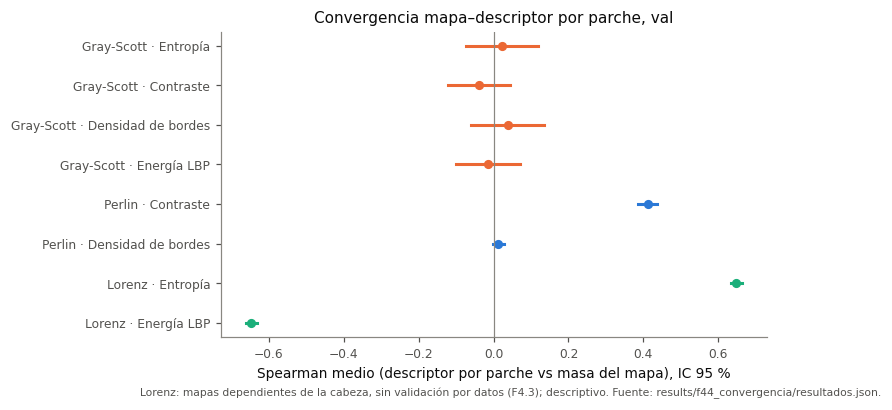

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
y = np.arange(len(TAB))[::-1]
for yi, (_, r) in zip(y, TAB.iterrows()):
    t = next(k for k, v in style.TECH_LABEL.items() if v == r['técnica'])
    ax.plot([r['IC inf'], r['IC sup']], [yi, yi], color=style.TECH_COLOR[t], lw=2)
    ax.plot(r['Spearman medio'], yi, 'o', color=style.TECH_COLOR[t])
ax.axvline(0, color=style.MUTED, lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels([f"{r['técnica']} · {r['descriptor']}" for _, r in TAB.iterrows()])
ax.set_xlabel('Spearman medio (descriptor por parche vs masa del mapa), IC 95 %')
ax.set_title('Convergencia mapa–descriptor por parche, val')
fig.text(0.01, -0.04, 'Lorenz: mapas dependientes de la cabeza, sin validación por datos (F4.3); descriptivo. '
         'Fuente: results/f44_convergencia/resultados.json.', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY)
guardar(fig, 'f44_01_spearman_ic', 'Spearman medio descriptor–masa por parche con IC 95 %, val')

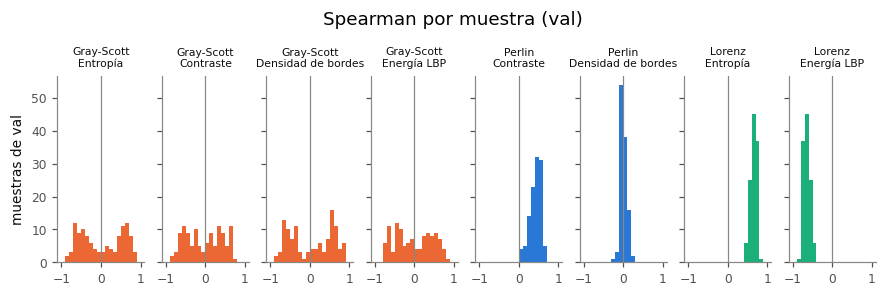

In [4]:
fig, axes = plt.subplots(1, 8, figsize=(9.6, 2.2), sharey=True)
for ax, (_, r) in zip(axes, TAB.iterrows()):
    t = next(k for k, v in style.TECH_LABEL.items() if v == r['técnica'])
    d = next(k for k, v in NOMBRE.items() if v == r['descriptor'])
    v = POR[(POR.tecnica == t) & (POR.descriptor == d) & (POR.mapa == 'map')]['spearman'].dropna()
    ax.hist(v, bins=np.linspace(-1, 1, 21), color=style.TECH_COLOR[t])
    ax.axvline(0, color=style.MUTED, lw=0.8)
    ax.set_title(f"{r['técnica']}\n{r['descriptor']}", fontsize=style.FONT_SIZES['annot'])
axes[0].set_ylabel('muestras de val')
fig.suptitle('Spearman por muestra (val)', y=1.15)
guardar(fig, 'f44_02_spearman_por_muestra', 'Distribución del Spearman por muestra, val')

## 2. Tabla cualitativa ablación (F4.3) ↔ descriptores (Tabla 11)

ΔF1 de la ablación (`f43.*`, `val`) y descriptores significativos con su d de Cohen (Tabla 11, `train`), ordenados por |d|. La columna «naturaleza» es una clasificación orientativa (resolución P6; el contraste no se asigna a ninguna banda).

In [5]:
rows = []
for t, x in R['tabla_cualitativa'].items():
    abl = '; '.join(f"{b.replace('paso_', '')} " + ' '.join(f"{s}={v:+.3f}" for s, v in x['delta_f1'][b].items())
                    for b in ('paso_bajo', 'paso_alto'))
    for dd in x['descriptores']:
        rows.append({'técnica': style.TECH_LABEL[t], 'ΔF1 ablación (σ)': abl, 'descriptor': NOMBRE[dd['descriptor']],
                     'd de Cohen': dd['cohen_d'], '|d|': dd['abs_d'], 'naturaleza (orientativa)': dd['naturaleza'],
                     'Spearman medio (F4.4)': R['spearman'][t]['map'][dd['descriptor']]['media']})
pd.DataFrame(rows)

,técnica,ΔF1 ablación (σ),descriptor,d de Cohen,|d|,naturaleza (orientativa),Spearman medio (F4.4)
0,Gray-Scott,bajo s1=-0.024 s2=-0.055 s4=-0.161 s8=-0.261; alto s1=-0.210 s2=-0.205 s4=-0.206 s8=-0.166,Energía LBP,1.319624,1.319624,"textura local, vecindad de radio 3 px (frecuencias altas y medias)",-0.015767
1,Gray-Scott,bajo s1=-0.024 s2=-0.055 s4=-0.161 s8=-0.261; alto s1=-0.210 s2=-0.205 s4=-0.206 s8=-0.166,Entropía,-1.097727,1.097727,histograma de niveles de gris (sin estructura espacial),0.022838
2,Gray-Scott,bajo s1=-0.024 s2=-0.055 s4=-0.161 s8=-0.261; alto s1=-0.210 s2=-0.205 s4=-0.206 s8=-0.166,Densidad de bordes,-0.656618,0.656618,bordes de Sobel (frecuencias altas),0.038934
3,Gray-Scott,bajo s1=-0.024 s2=-0.055 s4=-0.161 s8=-0.261; alto s1=-0.210 s2=-0.205 s4=-0.206 s8=-0.166,Contraste,-0.394960,0.394960,dispersión global de intensidades (sin banda específica),-0.037633
4,Perlin,bajo s1=-0.076 s2=-0.080 s4=-0.160 s8=-0.154; alto s1=-0.059 s2=-0.046 s4=-0.033 s8=-0.029,Densidad de bordes,0.945056,0.945056,bordes de Sobel (frecuencias altas),0.012513
5,Perlin,bajo s1=-0.076 s2=-0.080 s4=-0.160 s8=-0.154; alto s1=-0.059 s2=-0.046 s4=-0.033 s8=-0.029,Contraste,0.258013,0.258013,dispersión global de intensidades (sin banda específica),0.412283
6,Lorenz,bajo s1=-0.002 s2=-0.019 s4=-0.057 s8=-0.174; alto s1=-0.281 s2=-0.121 s4=-0.112 s8=-0.098,Energía LBP,0.443220,0.443220,"textura local, vecindad de radio 3 px (frecuencias altas y medias)",-0.647323
7,Lorenz,bajo s1=-0.002 s2=-0.019 s4=-0.057 s8=-0.174; alto s1=-0.281 s2=-0.121 s4=-0.112 s8=-0.098,Entropía,-0.422675,0.422675,histograma de niveles de gris (sin estructura espacial),0.648163


## 3. Contexto: contraste visual − descriptores de la Fase 5 (A11), citado sin combinar

In [6]:
pd.DataFrame([{'técnica': style.TECH_LABEL[t], 'clave': x['clave'], 'ΔF1 (prueba)': x['delta'], 'IC inf': x['ic_inf'],
               'IC sup': x['ic_sup']} for t, x in R['contexto_a11'].items()])

,técnica,clave,ΔF1 (prueba),IC inf,IC sup
0,Gray-Scott,f5.frente_a_descriptores.gray_scott,0.045434,-0.016468,0.109108
1,Perlin,f5.frente_a_descriptores.perlin,0.029797,-0.048729,0.108983
2,Lorenz,f5.frente_a_descriptores.lorenz,0.145432,0.048534,0.243425


In [7]:
pd.DataFrame([{'técnica': style.TECH_LABEL[t], 'lectura de F4.3': v} for t, v in R['lectura_f43'].items()])

,técnica,lectura de F4.3
0,Perlin,cordura_por_datos_superada
1,Lorenz,dependiente_de_la_cabeza_sin_validacion_por_datos


## 4. Ejemplos de parches: descriptor y masa

Para cada (técnica, descriptor), la muestra de `val` cuyo Spearman está más cerca de la mediana. Imagen redimensionada a 224 (la del descriptor, P1), descriptor por parche y masa del mapa por parche (`parches.npz`).

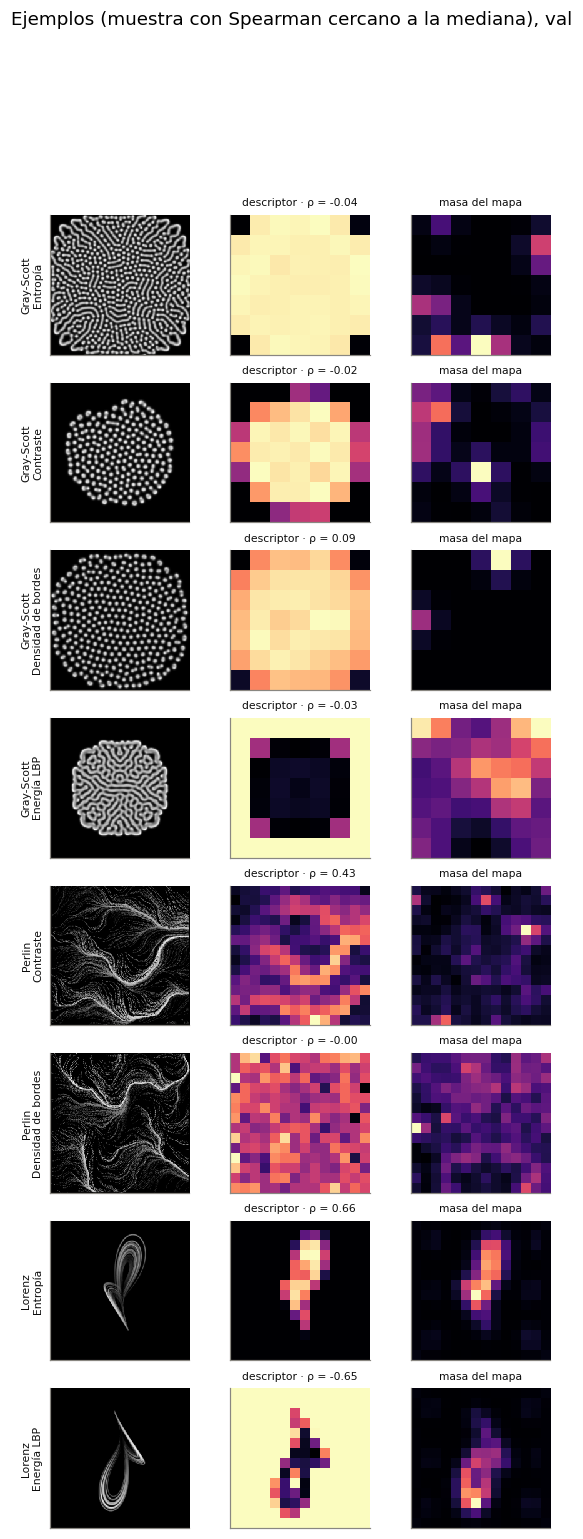

In [8]:
imgs = {}
for t in cv.TECNICAS:
    im, ids, _ = cv.cargar_imagenes_val(t)
    prep = cv.preprocesamiento(t)
    imgs[t] = np.stack([cv.redimensionar_224(a, prep) for a in im])
fig, axes = plt.subplots(8, 3, figsize=(6.0, 15.5))
for i, (_, r) in enumerate(TAB.iterrows()):
    t = next(k for k, v in style.TECH_LABEL.items() if v == r['técnica'])
    d = next(k for k, v in NOMBRE.items() if v == r['descriptor'])
    v = POR[(POR.tecnica == t) & (POR.descriptor == d) & (POR.mapa == 'map')].reset_index(drop=True)
    j = int((v['spearman'] - v['spearman'].median()).abs().idxmin())
    desc, masa = PAR[f'{t}|descriptor|{d}'][j], PAR[f'{t}|masa|map'][j]
    assert np.isclose(cv.spearman_por_muestra(desc[None], masa[None])[0], v['spearman'][j])
    axes[i, 0].imshow(imgs[t][j], cmap='gray', vmin=0, vmax=255)
    axes[i, 0].set_ylabel(f"{r['técnica']}\n{r['descriptor']}", fontsize=style.FONT_SIZES['annot'])
    axes[i, 1].imshow(desc, cmap='magma')
    axes[i, 2].imshow(masa, cmap='magma')
    axes[i, 1].set_title(f"descriptor · ρ = {v['spearman'][j]:.2f}", fontsize=style.FONT_SIZES['annot'])
    axes[i, 2].set_title('masa del mapa', fontsize=style.FONT_SIZES['annot'])
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('Ejemplos (muestra con Spearman cercano a la mediana), val', y=1.0)
guardar(fig, 'f44_03_ejemplos_parches', 'Ejemplos de descriptor y masa por parche, val')

## 5. Figuras generadas

In [9]:
pd.DataFrame(FIGS)

,archivo,figura
0,results/f44_convergencia/figures/f44_01_spearman_ic.png,"Spearman medio descriptor–masa por parche con IC 95 %, val"
1,results/f44_convergencia/figures/f44_02_spearman_por_muestra.png,"Distribución del Spearman por muestra, val"
2,results/f44_convergencia/figures/f44_03_ejemplos_parches.png,"Ejemplos de descriptor y masa por parche, val"
